In [99]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Regla del Trapecio.

Vamos a leer los datos y a gráficar los datos para ver como se comportan 

In [100]:
# Vamos a leer los archivos usando un programa que ya teniamos de la tarea 3 

entrada = open("data/velocidades.txt", "r")    # esto es un buffer
datos = [[], []]
for linea in entrada:
    #print(linea)
    palabras = linea.split()
    palabras = list(map(float, palabras))
    for j in range(len(palabras)):
        datos[j].append(palabras[j])

    #print(palabras)
datos = np.array(datos)

la cantidad de datos de tiempo es 101


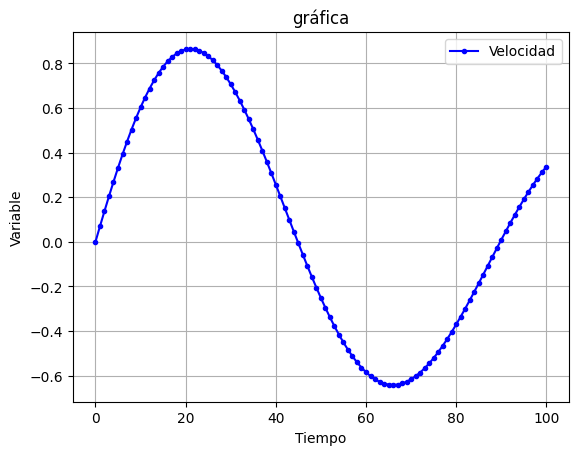

In [101]:
tiempo, velocidad = datos[0], datos[1]
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(tiempo, velocidad, label = "Velocidad", marker = ".", c = "blue")
plt.grid()
plt.legend(loc = "best")


## Distancia recorrida
Vamos a calcular la distancia recorrida en la dirección $x$, para ello notemos lo siguiente:

$$
\begin{aligned}
\text{Distancia total}
&= \frac{1}{2}\Big[
(t_1-t_0)(f(t_1)+f(t_0))\\
&\quad +(t_2-t_1)(f(t_2)+f(t_1))\\
&\quad +(t_3-t_2)(f(t_3)+f(t_2))\\
&\quad +\cdots
+(t_{101}-t_{100})(f(t_{101})+f(t_{100}))
\Big]\\[10pt]
&= \frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
\left[f(t_i)+f(t_{i+1})\right]
\right]
\end{aligned}
$$

Si definimos:

$$
f(t_i)=|V_i|
$$

Entonces:

$$
\boxed{
\text{Distancia total}
=
\frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
(|V_i|+|V_{i+1}|)
\right]
}
$$
Para sacar la base correcta debemos considerar que la función es positiva

In [102]:
Distancia = 0 #Definimos nuestras variables

for i in range(0,len(tiempo)-1):
    Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
    #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
distancia_total = Distancia/2
print(f"La distancia recorrida total es {distancia_total:.4} m")

La distancia recorrida total es 44.77 m


Para cada t, la distancia en el instante t se tiene lo siguiente

In [103]:
def distancia_recorrida(t):
    t = int(t)
    Distancia = 0 #Definimos nuestras variables
    if t>= 0 and t <= 100:
        for i in range(0,t):
            Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
            #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
        
        return Distancia/2
    if t>100 or t<0:
        print("Tu número debe de estar entre 0 y 100")
        return None
    

In [104]:
distancia= []
for i in range(0,101):
    print(f"la distancia recorrida en el instante t = {i} es {distancia_recorrida(i)}")
    distancia.append(distancia_recorrida(i))

la distancia recorrida en el instante t = 0 es 0.0
la distancia recorrida en el instante t = 1 es 0.034739
la distancia recorrida en el instante t = 2 es 0.138325
la distancia recorrida en el instante t = 3 es 0.309338
la distancia recorrida en el instante t = 4 es 0.5460455
la distancia recorrida en el instante t = 5 es 0.8464149999999999
la distancia recorrida en el instante t = 6 es 1.2081285
la distancia recorrida en el instante t = 7 es 1.6285975
la distancia recorrida en el instante t = 8 es 2.10498
la distancia recorrida en el instante t = 9 es 2.6341965
la distancia recorrida en el instante t = 10 es 3.212949
la distancia recorrida en el instante t = 11 es 3.83774
la distancia recorrida en el instante t = 12 es 4.504892
la distancia recorrida en el instante t = 13 es 5.2105685
la distancia recorrida en el instante t = 14 es 5.9507945
la distancia recorrida en el instante t = 15 es 6.721477999999999
la distancia recorrida en el instante t = 16 es 7.518431999999999
la distancia r

la cantidad de datos de tiempo es 101


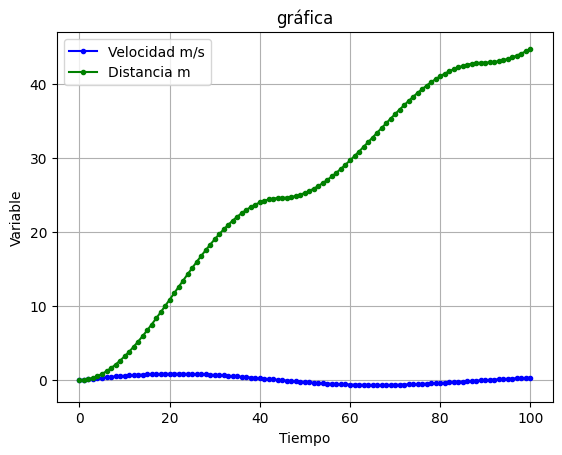

In [105]:
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(velocidad, label = "Velocidad m/s", marker = ".", c = "blue")
plt.plot( distancia, label = "Distancia m", marker = ".", c = "green")
plt.grid()
plt.legend(loc = "best")

# Ejercicio 2 

In [106]:
# Primero tenemos que la integral de Simpson está dada por: 
# Dada una función, tenemos un N = lo que quiera, y los límites de integración son a y b 

def IntegralSimpson(f, N, a,b):
    if N<= 0 or N % 2 != 0: 
        raise ValueError("N debe ser positivo y par")
    else:
        h = (b-a)/N
        suma_par = 0 
        suma_impar = 0 
        for i in range(1,int((N/2))):
            suma_par += f(a+(2*i*h))
        for i in range(1,int((N/2))+1):
            suma_impar += f(a+(2*i-1)*h)
        return (h/3)* ((f(a)+f(b))  + (4 * suma_impar) + (2 * suma_par))

## Inciso a) Escribir las funciones de Bessel

In [107]:
# Vamos a definir la función que va a dentro de la integral 
def cos_1(x,m, theta):
    return np.cos((m*theta)-(x*np.sin(theta)))

In [108]:
def J_Bessel(m, x):
    def f(theta):
        return cos_1(x, m, theta)

    return (1/np.pi)*IntegralSimpson(f, 1000, 0, np.pi)

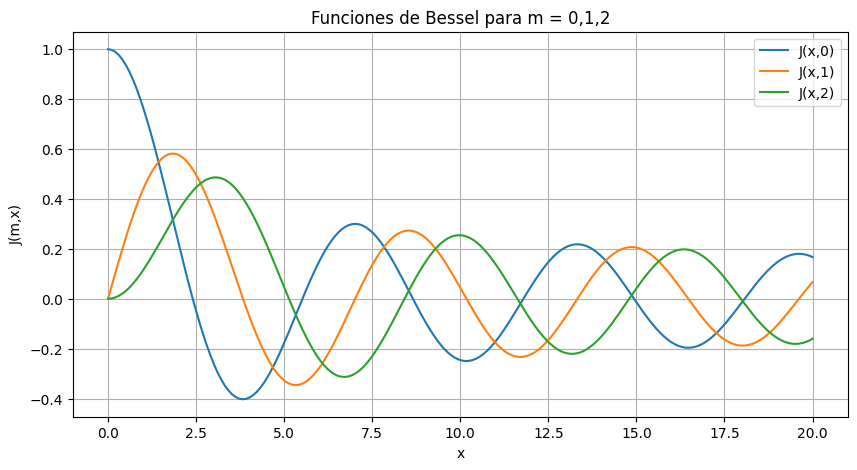

In [109]:
x_value = np.linspace(0,20, 200)
plt.figure(figsize=(10,5))
for i in range(3):
    plt.plot(x_value, J_Bessel(i, x_value), label = f"J(x,{i})")

plt.legend(loc = "best")
plt.title("Funciones de Bessel para m = 0,1,2")
plt.xlabel("x")
plt.ylabel("J(m,x)")
plt.grid()

## b) Comparación con scipy

In [110]:
from scipy.integrate import simpson

In [111]:
simpson?

Signature: simpson(y, x=None, *, dx=1.0, axis=-1)
Docstring:
Integrate y(x) using samples along the given axis and the composite
Simpson's rule. If x is None, spacing of dx is assumed.

Parameters
----------
y : array_like
    Array to be integrated.
x : array_like, optional
    If given, the points at which `y` is sampled.
dx : float, optional
    Spacing of integration points along axis of `x`. Only used when
    `x` is None. Default is 1.
axis : int, optional
    Axis along which to integrate. Default is the last axis.

Returns
-------
float
    The estimated integral computed with the composite Simpson's rule.

See Also
--------

:func:`quad`
    adaptive quadrature using QUADPACK
:func:`fixed_quad`
    fixed-order Gaussian quadrature
:func:`dblquad`
    double integrals
:func:`tplquad`
    triple integrals
:func:`romb`
    integrators for sampled data
:func:`cumulative_trapezoid`
    cumulative integration for sampled data
:func:`cumulative_simpson`
    cumulative integration usin

Tenemos que Scipy recibe valores de la función evaluada en los puntos de integración, Y = Puntos evaluados, x = puntos de evaluación 


In [112]:
# Función de Bessel calculada con SciPy
def J_Bessel_scipy(m, x):
    theta = np.linspace(0, np.pi)
    y_val = np.cos((m*theta)-(x*np.sin(theta)))
    return (1/np.pi) * simpson(y_val, theta)


In [113]:
x_value_sp = [[], [], []]
x_value = np.linspace(0,20, 200)
for i in x_value:
    for j in range(3):
        
        x_value_sp[j].append(J_Bessel_scipy(j,i))

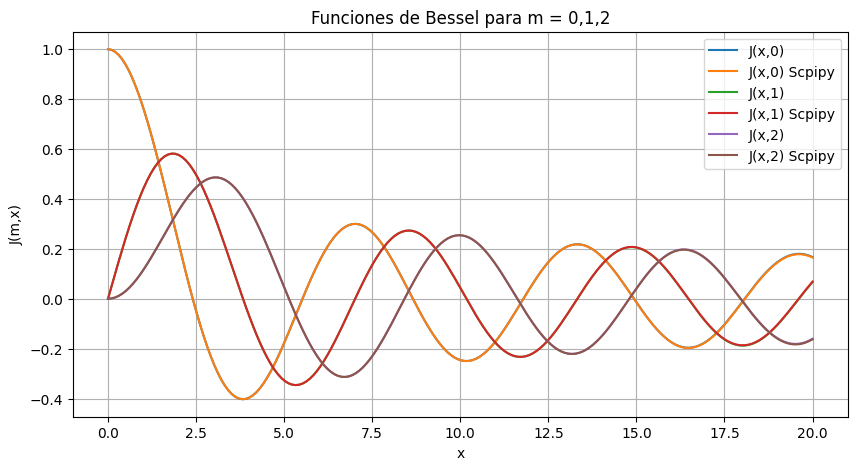

In [114]:

plt.figure(figsize=(10,5))
for i in range(3):
    plt.plot(x_value, J_Bessel(i, x_value), label = f"J(x,{i})")
    plt.plot(x_value, x_value_sp[i], label = f"J(x,{i}) Scpipy")
plt.legend(loc = "best")
plt.title("Funciones de Bessel para m = 0,1,2")
plt.xlabel("x")
plt.ylabel("J(m,x)")
plt.grid()

## c) Gráfica de densidad

In [115]:
# Primero creamos la fórmula de la Intensidad
def Intensidad(r,lamda):
    if r == 0:
        return 1/2
    if r>0 or r<0:
        k = (2*np.pi) / lamda
        return (J_Bessel(1, (k * r))/(k * r))**2

In [116]:
Intensidad(0, 0.550)

0.5

In [117]:
plt.imshow?

Signature:
plt.imshow(
    X: 'ArrayLike | PIL.Image.Image',
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    *,
    aspect: "Literal['equal', 'auto'] | float | None" = None,
    interpolation: 'str | None' = None,
    alpha: 'float | ArrayLike | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    colorizer: 'Colorizer | None' = None,
    origin: "Literal['upper', 'lower'] | None" = None,
    extent: 'tuple[float, float, float, float] | None' = None,
    interpolation_stage: "Literal['data', 'rgba', 'auto'] | None" = None,
    filternorm: 'bool' = True,
    filterrad: 'float' = 4.0,
    resample: 'bool | None' = None,
    url: 'str | None' = None,
    data=None,
    **kwargs,
) -> 'AxesImage'
Docstring:
Display data as an image, i.e., on a 2D regular raster.

The input may either be actual RGB(A) data, or 2D scalar data, which
will be rendered as a pseudocolor image. For displaying a grayscale
image, set up the col

In [118]:
np.meshgrid?

Signature:       np.meshgrid(*xi, copy=True, sparse=False, indexing='xy')
Call signature:  np.meshgrid(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function meshgrid at 0x0000022CFEFEF480>
File:            c:\users\piloto 01\anaconda3\envs\cursodemachinglearning\lib\site-packages\numpy\lib\_function_base_impl.py
Docstring:      
Return a tuple of coordinate matrices from coordinate vectors.

Make N-D coordinate arrays for vectorized evaluations of
N-D scalar/vector fields over N-D grids, given
one-dimensional coordinate arrays x1, x2,..., xn.

Parameters
----------
x1, x2,..., xn : array_like
    1-D arrays representing the coordinates of a grid.
indexing : {'xy', 'ij'}, optional
    Cartesian ('xy', default) or matrix ('ij') indexing of output.
    See Notes for more details.
sparse : bool, optional
    If True the shape of the returned coordinate array for dimension *i*
    is reduced from ``(N1, ..., Ni, ... Nn)`` to
    ``(1, ..., 1, Ni, 1, ..., 1)``

In [119]:
x = np.linspace(-1, 1, 100)
y = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x, y)
R = (X**2  + Y ** 2)**(1/2)
R.shape

(100, 100)

In [120]:
#Creamos la matriz de ceros 
Z = np.zeros(R.shape)

In [121]:
for i in range(100):
    for j in range(100):
        Z[i,j] = Intensidad(R[i,j], 0.550)

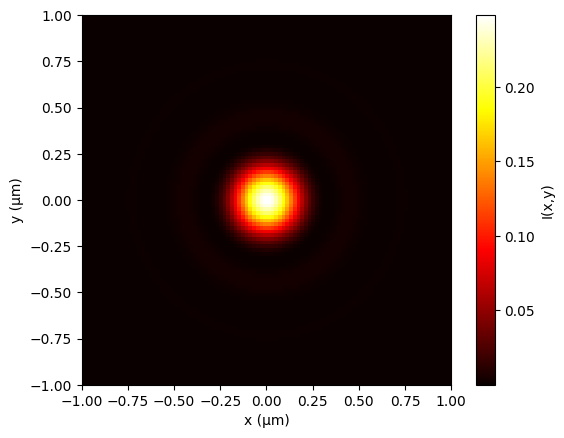

In [122]:
plt.imshow(Z, extent=[-1, 1, -1, 1], origin="lower", cmap="hot")
plt.colorbar(label="I(x,y)")
plt.xlabel("x (μm)")
plt.ylabel("y (μm)")
plt.show()

# 3. Capacidad calorífica de un sólido

## a) Función de capacidad calorífica de un sólido

In [123]:
# Importamos la libreria para obtener los polinomios de legengre
from numpy.polynomial.legendre import Legendre


### Vamos a poner un ejemplo de como se utilizan los polinomios de legendre para N = 50, y el intervalo x = [-1, 1]

In [124]:
N = 50 
x_1 = np.linspace(-1,1, 10*N)

P = Legendre.basis(N)  # Polinomio P_2(x)

print(P(x_1))          # Evalúa P_2(0.5)
print(P.roots())       # Calcula sus raíces
print(P.deriv()(x_1))  # Evalúa su derivada en x=0.5

[ 1.         -0.31537625  0.24337831  0.20777621 -0.10392835 -0.25027616
 -0.15385099  0.04584444  0.19224706  0.21108322  0.11706925 -0.02495471
 -0.14486842 -0.19727311 -0.17168213 -0.08712931  0.02130084  0.11706219
  0.17322173  0.17802635  0.13509715  0.05969078 -0.0270337  -0.10391658
 -0.15451907 -0.16993024 -0.14950643 -0.09983577 -0.03248907  0.03878772
  0.10082958  0.14328742  0.16005665  0.14980355  0.11565486  0.0642335
  0.00428828 -0.05481888 -0.10452955 -0.13822376 -0.1519568  -0.1447527
 -0.11847422 -0.07734038 -0.02719641  0.02534379  0.07376366  0.11241486
  0.13711402  0.14551659  0.13724974  0.11381547  0.07829798  0.03492641
 -0.01144685 -0.05589027 -0.09390246 -0.12183873 -0.1372207  -0.13890927
 -0.12713642 -0.10340499 -0.07027694 -0.03107869  0.01044309  0.05048046
  0.08550527  0.11256401  0.12950456  0.13512063  0.12920794  0.11253361
  0.08672758  0.05411004  0.01747328 -0.02016189 -0.05579436 -0.08667599
 -0.11051309 -0.12562276 -0.13103513 -0.12653729 -0.1

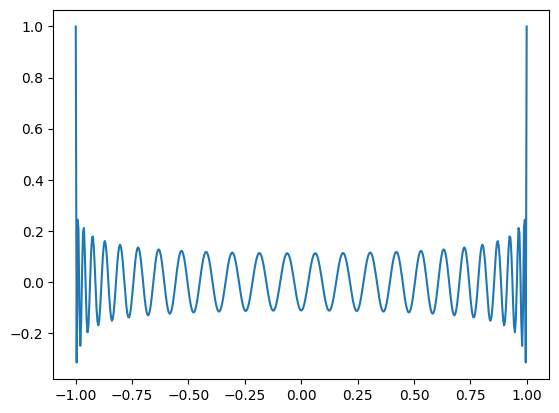

In [125]:
plt.plot(x_1, P(x_1))
#plt.plot(x_1,P.deriv()(x_1))

In [126]:
# Vamos a construir los w_k 
def w_k_f(N, a, b):
    w_k_array = []
    P = Legendre.basis(N)
    x = P.roots()
    for i in range(N):
        w_k = ((b-a)/2)*(2/ (1-x[i]**2)) * (P.deriv()(x[i]))**(-2)
        w_k_array.append(w_k)
    w_k_array = np.array(w_k_array)
    return w_k_array


In [127]:
pesos = w_k_f(50, -1, 1)

print(pesos)
print("Suma de pesos:", np.sum(pesos))

[0.00290862 0.0067598  0.01059055 0.01438082 0.01811556 0.02178024
 0.02536067 0.02884299 0.03221373 0.03545984 0.03856876 0.04152846
 0.0443275  0.04695505 0.04940094 0.0516557  0.05371062 0.05555774
 0.05718993 0.05860085 0.05978506 0.06073797 0.0614559  0.06193607
 0.06217662 0.06217662 0.06193607 0.0614559  0.06073797 0.05978506
 0.05860085 0.05718993 0.05555774 0.05371062 0.0516557  0.04940094
 0.04695505 0.0443275  0.04152846 0.03856876 0.03545984 0.03221373
 0.02884299 0.02536067 0.02178024 0.01811556 0.01438082 0.01059055
 0.0067598  0.00290862]
Suma de pesos: 2.0000000000000075


In [128]:
def integralGauss_Legendre(f, N, a, b):
    integral_v = 0

    P = Legendre.basis(N)
    x_k = P.roots()
    pesos = w_k_f(N, a, b)

    for k in range(N):
        x_p = ((b-a)/2)*x_k[k] + (b+a)/2
        integral_v += pesos[k]*f(x_p)

    return integral_v

In [129]:
# Constantes físicas
V = 1000 * 1e-6
rho = 6.022e28
k_B = 1.380649e-23
theta_D = 428
N = 50

# Integrando de Debye
def f(x):
    return x**4 * np.exp(x) / (np.expm1(x)**2)

# Capacidad calorífica
def Cv(T):
    a = 0
    b = theta_D / T

    integral = integralGauss_Legendre(f, N, a, b)

    return 9 * V * rho * k_B * (T/theta_D)**3 * integral

In [130]:
T = 300
print(f"Cv({T} K) = {Cv(T)} J/K")

Cv(300 K) = 2257.7973049456045 J/K


## Inciso b) 
Gráfica de la función 

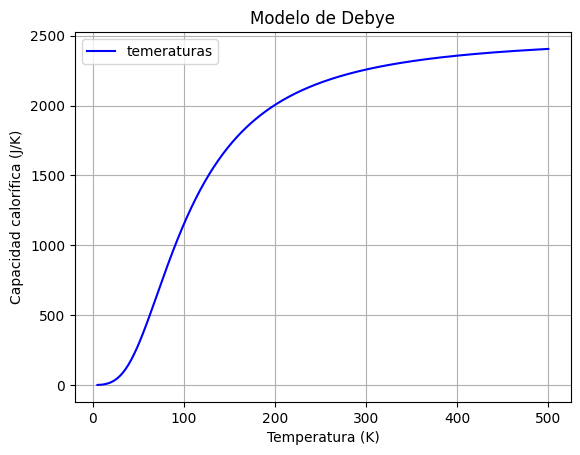

In [131]:
T = np.arange(5, 501, 1)
C_v = Cv(T)
plt.plot(T,C_v, label = "temeraturas", color = "blue")

plt.xlabel("Temperatura (K)")
plt.ylabel("Capacidad calorífica (J/K)")
plt.title("Modelo de Debye")
plt.legend()
plt.grid()
plt.show()

# 4. Incertidumbre cuántica en el oscilador armónico

## a ) Función H_n(x)

In [132]:
# Creamos la función de hermite de manera recursiva
def hermite(n,x):
    n = int(n)
    if n<0:
        raise ValueError("N debe ser positivo")
    if n == 0:
        return 1
    if n == 1:
        return 2*x
    if n>= 0: 
        return 2* x* hermite((n-1), x) - 2* (n-1) * hermite((n-2), x)


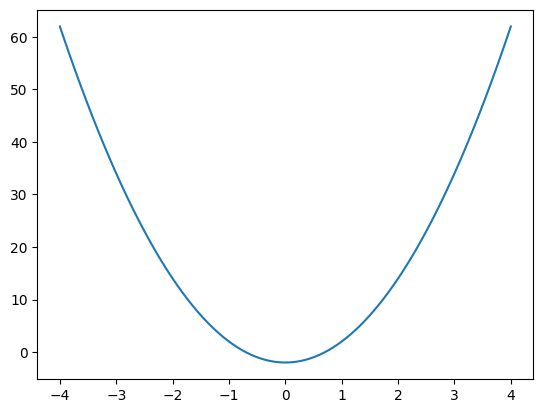

In [133]:
x_1 = np.linspace(-4,4, 100)
hermite(1,x_1).shape
plt.plot(x_1, hermite(2, x_1)) 

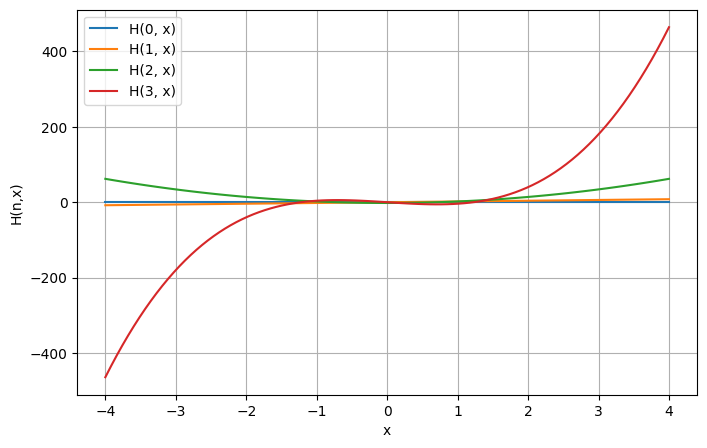

In [134]:
plt.figure(figsize=(8,5))
for i in range(0,4):
    if i == 0:
        plt.plot(x_1, np.ones(len(x_1)), label = f"H({i}, x)")
    if i != 0:
        plt.plot(x_1, hermite(i, x_1), label = f"H({i}, x)" )
plt.legend(loc = "best")
plt.xlabel("x")
plt.ylabel("H(n,x)")
plt.grid()

## b) Función de onda 

In [135]:
import math as mt

In [136]:
def funcion_de_onda(n,x):
    return (1/(np.sqrt((2**n)*(mt.factorial(n))*np.sqrt(np.pi)))) * np.exp(-(x**2)/2)*hermite(n,x)

In [137]:
x_2 = np.linspace(-10,10, 250)
y_2 = funcion_de_onda(30, x_2)


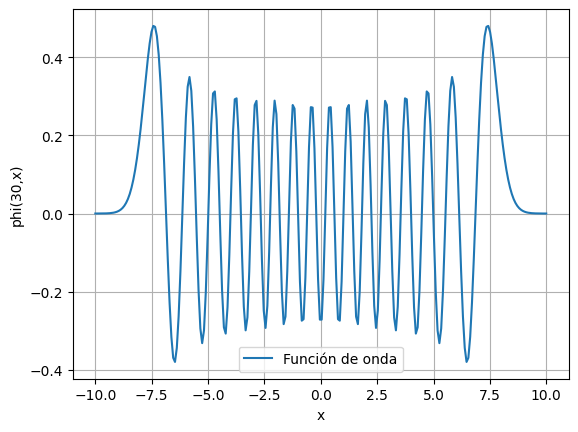

In [138]:
plt.plot(x_2, y_2, label = "Función de onda")
plt.legend(loc = "best")
plt.xlabel("x")
plt.ylabel("phi(30,x)")
plt.grid()

In [139]:
def promedio(x):
    n = 5
    return x**2 * np.abs(funcion_de_onda(n, x))**2

In [140]:
resultado = integralGauss_Legendre(promedio, 1000, -100, 100)

print(resultado)
print("Incertidumbre:", np.sqrt(resultado))

5.499999999999903
Incertidumbre: 2.345207879911694


# 5. Atracción gravitacional de una lámina uniforme

## a)Fuerza gravitacional de una lámina cuadrada uniforme



### Planteamiento del problema

Una lámina metálica cuadrada uniforme se encuentra en el plano $xy$, centrada en el origen. Una masa puntual de $1\,\mathrm{kg}$ está situada sobre el eje $z$, a una distancia $z$ del centro de la lámina.

La lámina tiene un lado de $10\,\mathrm{m}$, espesor despreciable y una masa de $10$ toneladas.

El objetivo es demostrar que la magnitud de la componente vertical de la fuerza gravitacional es

$$
\boxed{
F_z=G\sigma z
\int_{-L/2}^{L/2}
\int_{-L/2}^{L/2}
\frac{dx\,dy}{(x^2+y^2+z^2)^{3/2}}
}
$$

donde $\sigma$ es la densidad superficial de masa y $G$ es la constante gravitacional.



### 1. Datos del problema

Los datos proporcionados son:

- Longitud del lado: $L=10\,\mathrm{m}$.
- Masa de la lámina: $M=10\,000\,\mathrm{kg}$.
- Masa puntual: $m=1\,\mathrm{kg}$.
- Constante gravitacional: $G=6.674\times10^{-11}\,\mathrm{m^3\,kg^{-1}\,s^{-2}}$.
- Distancia perpendicular a la lámina: $z$.

Como la lámina tiene una distribución uniforme de masa, su densidad superficial está definida por

$$
\sigma=\frac{M}{A}.
$$

Dado que el área de la lámina cuadrada es

$$
A=L^2,
$$

se obtiene

$$
\sigma=\frac{M}{L^2}.
$$

Sustituyendo los valores:

$$
\sigma=\frac{10\,000}{(10)^2}.
$$

Por tanto,

$$
\boxed{\sigma=100\,\mathrm{kg/m^2}}
$$


### 2. Aplicación de la ley de gravitación universal

La ley de gravitación universal de Newton establece que la magnitud de la fuerza gravitacional entre dos masas puntuales está dada por

$$
F=G\frac{m_1m_2}{r^2}.
$$

Sin embargo, la lámina representa una distribución continua de masa. Por lo tanto, debemos dividirla en elementos diferenciales.

Consideremos un elemento diferencial de área $dA$ situado en la posición $(x,y,0)$.

Como la lámina está contenida en el plano $xy$, tenemos

$$
dA=dx\,dy.
$$

La masa correspondiente a dicho elemento es

$$
\boxed{dm=\sigma\,dx\,dy}.
$$

La magnitud de la fuerza gravitacional diferencial que ejerce $dm$ sobre la masa puntual $m$ es

$$
dF=G\frac{m\,dm}{r^2}.
$$

Sustituyendo la expresión de $dm$:

$$
\boxed{
dF=G\frac{m\sigma\,dx\,dy}{r^2}
}
$$


### 3. Determinación de la distancia entre las masas

El elemento diferencial de masa se encuentra en la posición

$$
\mathbf{r}'=x\hat{\mathbf{x}}+y\hat{\mathbf{y}}.
$$

Mientras que la masa puntual está localizada en

$$
\mathbf{r}=z\hat{\mathbf{z}}.
$$

El vector que va desde el elemento de masa hasta la masa puntual es

$$
\mathbf{R}=\mathbf{r}-\mathbf{r}'.
$$

Sustituyendo:

$$
\mathbf{R}
=-x\hat{\mathbf{x}}
-y\hat{\mathbf{y}}
+z\hat{\mathbf{z}}.
$$

Su magnitud está dada por

$$
r=|\mathbf{R}|.
$$

Por tanto,

$$
r=\sqrt{x^2+y^2+z^2}.
$$

Elevando al cuadrado:

$$
\boxed{r^2=x^2+y^2+z^2}
$$

Sustituyendo en la expresión de la fuerza diferencial:

$$
dF=
G\frac{m\sigma\,dx\,dy}
{x^2+y^2+z^2}.
$$



### 4. Componente gravitacional sobre el eje $z$

La fuerza gravitacional es atractiva, por lo que está dirigida desde la masa puntual hacia el elemento diferencial de la lámina.

Para determinar su componente vertical utilizamos la proyección

$$
dF_z=-dF\cos\theta.
$$

El signo negativo indica que la fuerza apunta en dirección contraria al eje $z$ positivo.

A partir de la geometría del sistema:

$$
\cos\theta=\frac{z}{r}.
$$

Sustituyendo la expresión de $r$:

$$
\cos\theta=
\frac{z}{\sqrt{x^2+y^2+z^2}}.
$$

Por lo tanto,

$$
dF_z=
-G\frac{m\sigma\,dx\,dy}
{x^2+y^2+z^2}
\frac{z}{\sqrt{x^2+y^2+z^2}}.
$$

Agrupando términos:

$$
dF_z=
-Gm\sigma z
\frac{dx\,dy}
{(x^2+y^2+z^2)\sqrt{x^2+y^2+z^2}}.
$$

Utilizando la propiedad de los exponentes:

$$
(x^2+y^2+z^2)
\sqrt{x^2+y^2+z^2}
=
(x^2+y^2+z^2)^{3/2},
$$

finalmente obtenemos

$$
\boxed{
dF_z=
-Gm\sigma z
\frac{dx\,dy}
{(x^2+y^2+z^2)^{3/2}}
}
$$

Esta expresión representa la componente vertical de la fuerza gravitacional producida por un elemento infinitesimal de masa.



### 5. Integración sobre toda la superficie

La componente vertical de la fuerza gravitacional total se obtiene sumando las contribuciones de todos los elementos diferenciales de la lámina.

Matemáticamente:

$$
F_z=\iint_A dF_z.
$$

Sustituyendo la expresión obtenida:

$$
F_z=
-Gm\sigma z
\iint_A
\frac{dA}
{(x^2+y^2+z^2)^{3/2}}.
$$

La lámina es cuadrada, de lado $L$, y está centrada en el origen.

Por lo tanto, sus límites de integración son

$$
-\frac{L}{2}\leq x\leq\frac{L}{2}
$$

y

$$
-\frac{L}{2}\leq y\leq\frac{L}{2}.
$$

Así, la integral de superficie puede expresarse como

$$
F_z=
-Gm\sigma z
\int_{-L/2}^{L/2}
\int_{-L/2}^{L/2}
\frac{dx\,dy}
{(x^2+y^2+z^2)^{3/2}}.
$$

Dado que la masa puntual es de $1\,\mathrm{kg}$, al sustituir su valor numérico en unidades del SI obtenemos

$$
\boxed{
F_z=
-G\sigma z
\int_{-L/2}^{L/2}
\int_{-L/2}^{L/2}
\frac{dx\,dy}
{(x^2+y^2+z^2)^{3/2}}
}
$$

Como el problema solicita la magnitud de la componente vertical, tenemos

$$
\boxed{
|F_z|=
G\sigma z
\int_{-L/2}^{L/2}
\int_{-L/2}^{L/2}
\frac{dx\,dy}
{(x^2+y^2+z^2)^{3/2}}
}
$$



## b) calcular y graficar la fuerza en funcón de z de z = 0

### Construcción de la integral doble

In [150]:
def integralGauss_Legendre_doble(f, N, a, b, c, d):
    integral_v_doble = 0

    P = Legendre.basis(N)
    x_k = P.roots()

    pesos_1 = w_k_f(N, a, b)
    pesos_2 = w_k_f(N, c, d)

    for k in range(N):
        x_p = ((b-a)/2)*x_k[k] + (b+a)/2

        for j in range(N):
            y_p = ((d-c)/2)*x_k[j] + (d+c)/2

            integral_v_doble += pesos_1[k]*pesos_2[j]*f(x_p, y_p)

    return integral_v_doble

In [151]:
def prueba_doble(x,y):
    return x*y

In [152]:
integralGauss_Legendre_doble(prueba_doble, 10, 0, 1, 0, 1)

np.float64(0.25000000000000067)

Para una lámina ideal infinitamente delgada:

$$
\boxed{
\lim_{z \to 0^+} F_z(z) = 2\pi G\sigma
}
$$

In [174]:
# Constantes físicas
G = 6.674e-11       # Constante gravitacional (N·m²/kg²)
M = 10000           # Masa de la lámina (kg)
m = 1               # Masa puntual (kg)
L = 10              # Lado de la lámina (m)

# Densidad superficial
sigma = M / L**2    # kg/m²

# Número de puntos de Gauss-Legendre
N = 100

In [181]:
def fuerza(z):
    def gravedad(x,y):
        if z == 0:
            
            if x== 0 and y == 0:
                return 2*G*np.pi * sigma
        if z != 0 or x != 0 or y != 0:
            return (x**2+y**2+z**2)**(-3/2)

    return G * sigma* integralGauss_Legendre_doble(gravedad,N,-(L/2),(L/2),-(L/2),(L/2))


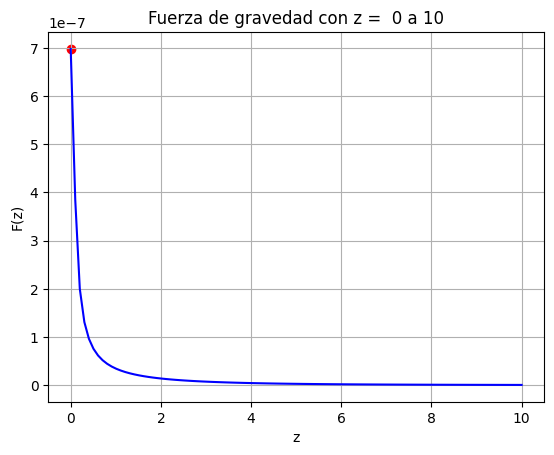

In [184]:
x_3 = np.linspace(0,10,100)
Fuerza = []
for i in x_3:
    Fuerza.append(fuerza(i))
plt.plot(x_3, Fuerza, color = "blue", label = "Puntos distintos de 0")
plt.scatter(0, fuerza(0), color = "red", label = "Punto critico")
plt.title("Fuerza de gravedad con z =  0 a 10")
plt.xlabel("z")
plt.ylabel("F(z)")
plt.grid()

### c). Análisis del artefacto numérico

La disminución artificial de la fuerza gravitacional para valores muy pequeños de \(z\) se debe a las limitaciones de la cuadratura de Gauss-Legendre cuando se utiliza un número finito de puntos de evaluación.

Al aproximarse \(z\) a cero, el integrando presenta un pico cada vez más pronunciado y estrecho alrededor del origen. Debido a que los puntos de cuadratura no se concentran suficientemente en esta región, el método subestima la contribución del integrando y, por consecuencia, la fuerza gravitacional calculada tiende artificialmente a cero.

Este comportamiento no corresponde al fenómeno físico, puesto que la magnitud de la fuerza tiene un límite finito y distinto de cero al aproximarse a la superficie desde arriba.

Para reducir este error numérico, se puede aumentar el número de puntos de cuadratura o subdividir el dominio de integración, utilizando una mayor resolución cerca del origen.

# Rejillas de difracción

## a). Separación entre rendijas

La función de transmisión de intensidad de la rejilla está dada por

$$
q(u)=\sin^2(\alpha u).
$$

Para determinar la separación entre rendijas, debemos encontrar la distancia entre dos máximos consecutivos de la función de transmisión, ya que estos representan las posiciones donde la luz se transmite con mayor intensidad.

### 1. Determinación de los máximos

Derivamos la función con respecto a $u$:

$$
\frac{dq}{du}=2\alpha\sin(\alpha u)\cos(\alpha u).
$$

Utilizando la identidad trigonométrica

$$
2\sin\theta\cos\theta=\sin(2\theta),
$$

obtenemos

$$
\frac{dq}{du}=\alpha\sin(2\alpha u).
$$

Para encontrar los puntos críticos, imponemos

$$
\frac{dq}{du}=0.
$$

Por tanto, suponiendo $\alpha\neq 0$,

$$
\sin(2\alpha u)=0.
$$

Sabemos que esta condición se satisface cuando

$$
2\alpha u=n\pi,\qquad n\in\mathbb{Z}.
$$

Despejando $u$:

$$
u_n=\frac{n\pi}{2\alpha}.
$$

Para identificar cuáles de estos puntos corresponden a máximos, calculamos la segunda derivada:

$$
\frac{d^2q}{du^2}=2\alpha^2\cos(2\alpha u).
$$

Evaluando en los puntos críticos:

$$
\frac{d^2q}{du^2}\bigg|_{u_n}
=2\alpha^2\cos(n\pi)
=2\alpha^2(-1)^n.
$$

Los máximos ocurren cuando la segunda derivada es negativa, es decir, cuando $n$ es impar.

Escribiendo $n=2m+1$, con $m\in\mathbb{Z}$, las posiciones de los máximos son

$$
\boxed{u_m=\frac{(2m+1)\pi}{2\alpha}}.
$$

### 2. Separación entre rendijas

La separación $d$ entre rendijas corresponde a la distancia entre dos máximos consecutivos de transmisión:

$$
d=|u_{m+1}-u_m|.
$$

Las posiciones de estos máximos son

$$
u_m=\frac{(2m+1)\pi}{2\alpha}
$$

y

$$
u_{m+1}=\frac{(2m+3)\pi}{2\alpha}.
$$

Sustituyendo:

$$
d=\left|\frac{(2m+3)\pi}{2\alpha}
-\frac{(2m+1)\pi}{2\alpha}\right|.
$$

Simplificando:

$$
d=\left|\frac{2\pi}{2\alpha}\right|.
$$

Por lo tanto,

$$
\boxed{d=\frac{\pi}{|\alpha|}}.
$$

Si consideramos $\alpha>0$, obtenemos

$$
\boxed{d=\frac{\pi}{\alpha}}.
$$



## b) función q(u)

In [ ]:
d = 20e-6
alpha = np.pi /d
def q(u):
    return np.sin(alpha*u)**2

## c) Gráfica

El método que se usó fue el método de la cuadratura, porque sabemos que es eficiente, la cantidad de puntos fueron considerando la eficiencia de la cpmputadora, porque con 100 puntos no se veía uniforme, sin embargo con 1000 puntos tardó 50 segundos en copilar (quizás sea por mi laptop), y con 300 se ven más suabes las curvas

In [190]:
# Intensidad del patrón
omega = 10*d
lambda_1 = 500e-9
f = 1 
a = -omega/2
b = omega/2
def Intensidad_patron(q,x):
    def integrando_1(u):
        return np.sqrt(q(u)) * np.exp((1j * 2 * np.pi * x* u)/(lambda_1 * f ))
    return np.abs(integralGauss_Legendre(integrando_1, 100, a, b))

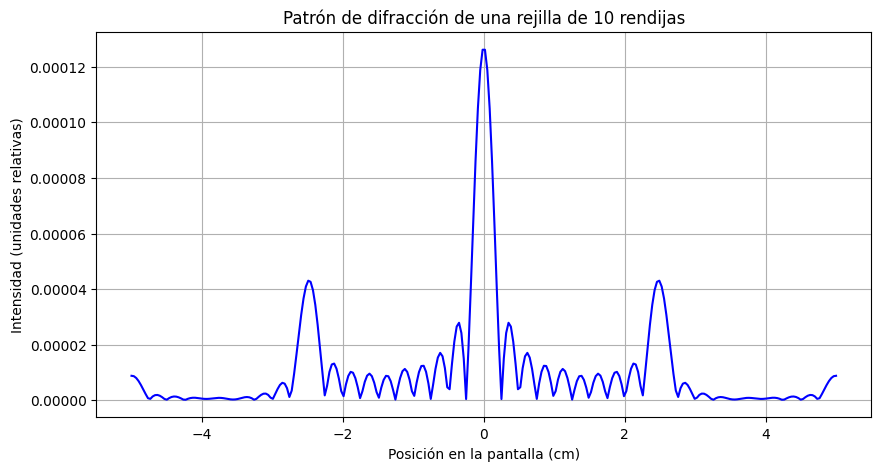

In [194]:
I = []
x = np.linspace(-0.05, 0.05, 300)

for x_i in x:
    I.append(Intensidad_patron(q, x_i))

I = np.array(I)

# Gráfica
plt.figure(figsize=(10, 5))
plt.plot(x*100, I, color="blue")
plt.xlabel("Posición en la pantalla (cm)")
plt.ylabel("Intensidad (unidades relativas)")
plt.title("Patrón de difracción de una rejilla de 10 rendijas")
plt.grid()
plt.show()

## d)grafico de densidad.

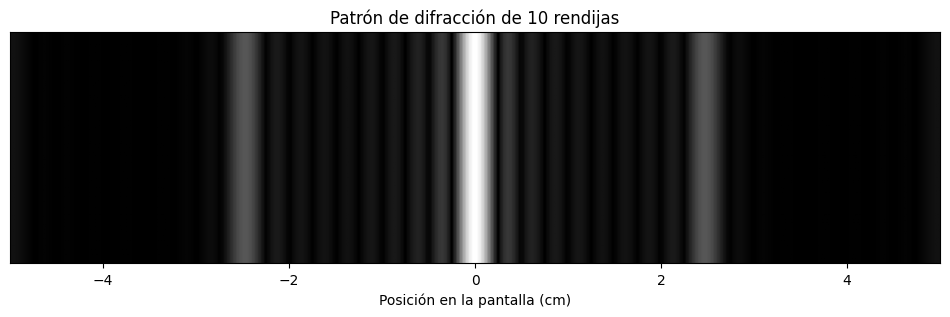

In [195]:
# Convertimos la intensidad en una matriz bidimensional
I_2D = np.tile(I, (100, 1))
plt.figure(figsize=(12, 3))
plt.imshow(I_2D,cmap="gray",extent=[-5, 5, -1, 1], aspect="auto", origin="lower")
plt.xlabel("Posición en la pantalla (cm)")
plt.yticks([])
plt.title("Patrón de difracción de 10 rendijas")
plt.show()

## e) Modificación


In [196]:
# Constantes
d = 20e-6
alpha = np.pi / d
beta = alpha / 2

omega = 10*d
lambda_1 = 500e-9
f = 1

a = -omega/2
b = omega/2

# Nueva función de transmisión
def q(u):
    return np.sin(alpha*u)**2 * np.sin(beta*u)**2

In [197]:
# Posiciones sobre la pantalla
x = np.linspace(-0.05, 0.05, 300)

# Nueva intensidad
I = []

for x_i in x:
    I.append(Intensidad_patron(q, x_i))

I = np.array(I)

Text(0.5, 1.0, 'Patrón de difracción: perfil modificado')

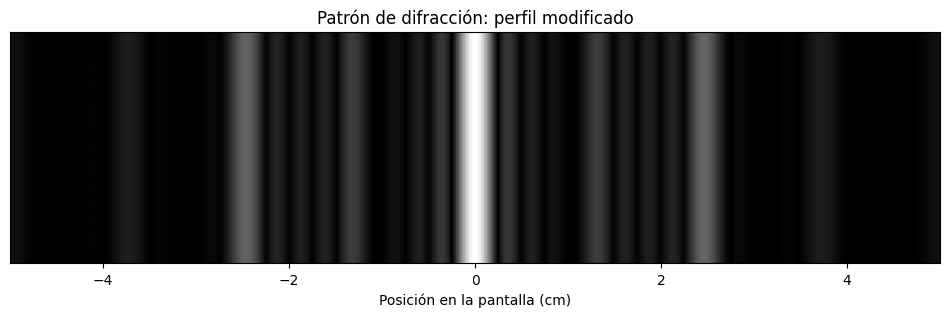

In [199]:
# Normalizamos la intensidad
I_normalizada = I / np.max(I)

# Construimos el gráfico de densidad
I_2D = np.tile(I_normalizada, (100, 1))
plt.figure(figsize=(12, 3))
plt.imshow( I_2D, cmap="gray", extent=[-5, 5, -1, 1], aspect="auto", origin="lower")
plt.xlabel("Posición en la pantalla (cm)")
plt.yticks([])
plt.title("Patrón de difracción: perfil modificado")

### III

In [200]:
# Anchuras de las rendijas
ancho_1 = 10e-6
ancho_2 = 20e-6

# Separación entre rendijas
separacion = 60e-6

# Límites de las rendijas
a1, b1 = -40e-6, -30e-6
a2, b2 = 30e-6, 50e-6

# Función de transmisión
def q(u):
    if a1 <= u <= b1:
        return 1
    elif a2 <= u <= b2:
        return 1
    else:
        return 0

In [201]:
# Constantes
lambda_1 = 500e-9
f = 1
N = 100

def Intensidad_patron_dos_rendijas(x):

    def integrando(u):
        return np.exp(
            1j * 2 * np.pi * x * u / (lambda_1 * f)
        )

    # Contribución de la primera rendija
    I_1 = integralGauss_Legendre(integrando, N, a1, b1)

    # Contribución de la segunda rendija
    I_2 = integralGauss_Legendre(integrando, N, a2, b2)

    # Suma de amplitudes e intensidad
    return np.abs(I_1 + I_2)**2

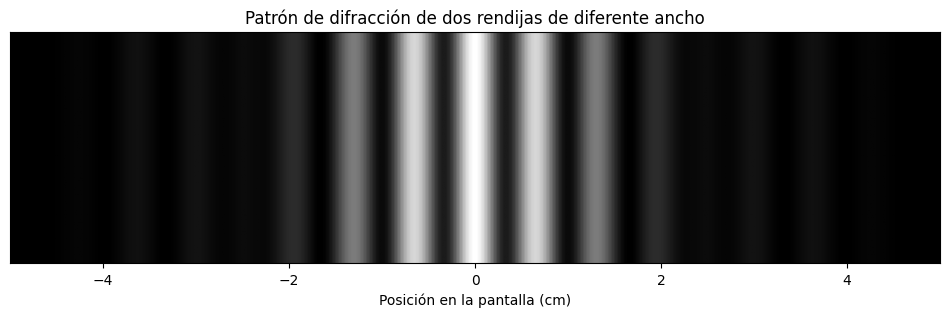

In [202]:
# Posiciones sobre la pantalla
x = np.linspace(-0.05, 0.05, 300)

# Calculamos la intensidad
I = []

for x_i in x:
    I.append(Intensidad_patron_dos_rendijas(x_i))

I = np.array(I)

# Normalizamos
I_normalizada = I / np.max(I)

# Construimos la imagen
I_2D = np.tile(I_normalizada, (100, 1))

plt.figure(figsize=(12, 3))

plt.imshow( I_2D, cmap="gray", extent=[-5, 5, -1, 1], aspect="auto", origin="lower")

plt.xlabel("Posición en la pantalla (cm)")
plt.yticks([])
plt.title("Patrón de difracción de dos rendijas de diferente ancho")
plt.show()